Total Points: 750 | Train Steps: 525 | Test Steps: 225

--- Training on Train Set ---
Epoch 300/1200 | Loss: 4.781753e-07 | delta: 0.218, alpha: -1.000, beta: 0.999
Epoch 600/1200 | Loss: 4.781753e-07 | delta: 0.218, alpha: -1.000, beta: 0.999
Epoch 900/1200 | Loss: 4.781751e-07 | delta: 0.218, alpha: -1.000, beta: 0.999
Epoch 1200/1200 | Loss: 4.781752e-07 | delta: 0.218, alpha: -1.000, beta: 0.999

--- Running Full Rollout Inference ---

[Train Results] R² Score: 0.9959 | RMSE: 0.01813
[Test Results]  R² Score: 0.9671 | RMSE: 0.02247
Learned Parameters -> delta: 0.2175, alpha: -1.0000, beta: 0.9993


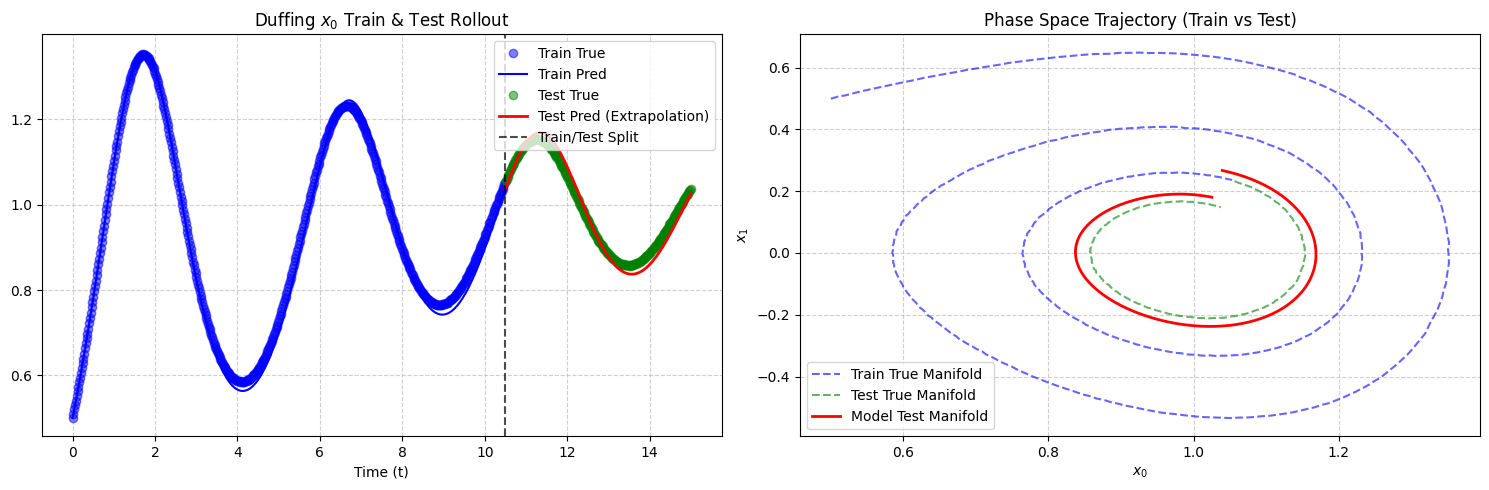

In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class DuffingSystemDataset:
    def __init__(self, u0=[0.5, 0.5], t_span=(0.0, 15.0), num_points=750, noise_level=0.0005):
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def ode_func(self, t, u):
        x0, x1 = u[0], u[1]
        delta = 0.2   # Sönümleme
        alpha = -1.0  # Doğrusal sertlik
        beta = 1.0    # Kübik non-linear sertlik
        
        dx0 = x1
        dx1 = -delta * x1 - alpha * x0 - beta * (x0**3)
        return [dx0, dx1]

    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        sol = solve_ivp(self.ode_func, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        return t_data, u_data, dt


class StructuredDuffingModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Öğrenilebilir fiziksel katsayılar (başlangıç tahminleri)
        self.delta = nn.Parameter(torch.tensor([0.15]))
        self.alpha = nn.Parameter(torch.tensor([-0.8]))
        self.beta = nn.Parameter(torch.tensor([0.8]))
        
    def forward(self, u):
        x0, x1 = u[:, 0:1], u[:, 1:2]
        dx0 = x1
        dx1 = -self.delta * x1 - self.alpha * x0 - self.beta * (x0 ** 3)
        return torch.cat([dx0, dx1], dim=-1)

    def train_model(self, u_train, dt, epochs=1200, lr=0.02):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=400, gamma=0.5)
        
        print("\n--- Training on Train Set ---")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            u_curr = u_train[:-1]
            u_next_true = u_train[1:]
            
            f_pred = self.forward(u_curr)
            u_next_pred = u_curr + f_pred * dt
            
            loss = torch.mean((u_next_pred - u_next_true) ** 2)
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            if (epoch + 1) % 300 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e} | "
                      f"delta: {self.delta.item():.3f}, alpha: {self.alpha.item():.3f}, beta: {self.beta.item():.3f}")

    def evaluate_rollout(self, u0, num_steps, dt):
        self.eval()
        preds = [u0.clone().detach()]
        curr = u0.clone().detach().unsqueeze(0)
        
        with torch.no_grad():
            for _ in range(num_steps - 1):
                f = self.forward(curr)
                next_state = curr + f * dt
                preds.append(next_state.squeeze(0).clone().detach())
                curr = next_state
                
        return torch.stack(preds)


if __name__ == "__main__":
    # 1. Veri Üretimi
    dataset_gen = DuffingSystemDataset(u0=[0.5, 0.5], t_span=(0.0, 15.0), num_points=750)
    t_data, u_data, dt = dataset_gen.generate()
    
    # 2. Kronolojik Train/Test Bölünmesi (%70 Train, %30 Test)
    split_idx = int(len(t_data) * 0.7)
    
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]
    
    print(f"Total Points: {len(t_data)} | Train Steps: {len(t_train)} | Test Steps: {len(t_test)}")

    # 3. Model Eğitimi (Sadece Train verisi ile)
    model = StructuredDuffingModel()
    model.train_model(u_train, dt, epochs=1200, lr=0.02)

    # 4. Tüm Zaman Serisi Üzerinde Rollout (Test performansını görmek için başlangıç noktası u_data[0])
    print("\n--- Running Full Rollout Inference ---")
    u_full_pred = model.evaluate_rollout(u_data[0], len(t_data), dt)
    
    # Train ve Test tahminlerini ayır
    u_train_pred = u_full_pred[:split_idx].numpy()
    u_test_pred = u_full_pred[split_idx:].numpy()
    
    u_train_np = u_train.numpy()
    u_test_np = u_test.numpy()
    t_train_np = t_train.numpy().flatten()
    t_test_np = t_test.numpy().flatten()

    # 5. Metrik Hesaplama (Train ve Test ayrı)
    def compute_metrics(y_true, y_pred):
        mse = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true, axis=0)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        return r2, rmse

    train_r2, train_rmse = compute_metrics(u_train_np, u_train_pred)
    test_r2, test_rmse = compute_metrics(u_test_np, u_test_pred)
    
    print(f"\n[Train Results] R² Score: {train_r2:.4f} | RMSE: {train_rmse:.5f}")
    print(f"[Test Results]  R² Score: {test_r2:.4f} | RMSE: {test_rmse:.5f}")
    print(f"Learned Parameters -> delta: {model.delta.item():.4f}, alpha: {model.alpha.item():.4f}, beta: {model.beta.item():.4f}")

    # 6. Görselleştirme (Train / Test ayrımını gösteren grafik)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Zaman Serisi Karşılaştırması ($x_0$)
    axes[0].plot(t_train_np, u_train_np[:, 0], 'bo', label='Train True', alpha=0.5)
    axes[0].plot(t_train_np, u_train_pred[:, 0], 'b-', label='Train Pred', linewidth=1.5)
    axes[0].plot(t_test_np, u_test_np[:, 0], 'go', label='Test True', alpha=0.5)
    axes[0].plot(t_test_np, u_test_pred[:, 0], 'r-', label='Test Pred (Extrapolation)', linewidth=2)
    axes[0].axvline(x=t_train_np[-1], color='k', linestyle='--', alpha=0.7, label='Train/Test Split')
    axes[0].set_title('Duffing $x_0$ Train & Test Rollout')
    axes[0].set_xlabel('Time (t)')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # Faz Uzayı Karşılaştırması ($x_0$ vs $x_1$)
    axes[1].plot(u_train_np[:, 0], u_train_np[:, 1], 'b--', label='Train True Manifold', alpha=0.6)
    axes[1].plot(u_test_np[:, 0], u_test_np[:, 1], 'g--', label='Test True Manifold', alpha=0.6)
    axes[1].plot(u_test_pred[:, 0], u_test_pred[:, 1], 'r-', label='Model Test Manifold', linewidth=2)
    axes[1].set_title('Phase Space Trajectory (Train vs Test)')
    axes[1].set_xlabel('$x_0$')
    axes[1].set_ylabel('$x_1$')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

Total Points: 750 | Train Steps: 525 | Test Steps: 225

--- Training on Van der Pol Train Set ---
Epoch 300/1200 | Loss: 2.705129e-06 | mu: 1.4975
Epoch 600/1200 | Loss: 2.705129e-06 | mu: 1.4975
Epoch 900/1200 | Loss: 2.705129e-06 | mu: 1.4975
Epoch 1200/1200 | Loss: 2.705129e-06 | mu: 1.4975

--- Running Van der Pol Rollout Inference ---

[Train Results] R² Score: 0.9595 | RMSE: 0.28224
[Test Results]  R² Score: 0.8377 | RMSE: 0.52870
Learned Parameter -> mu: 1.4975 (True: 1.5000)


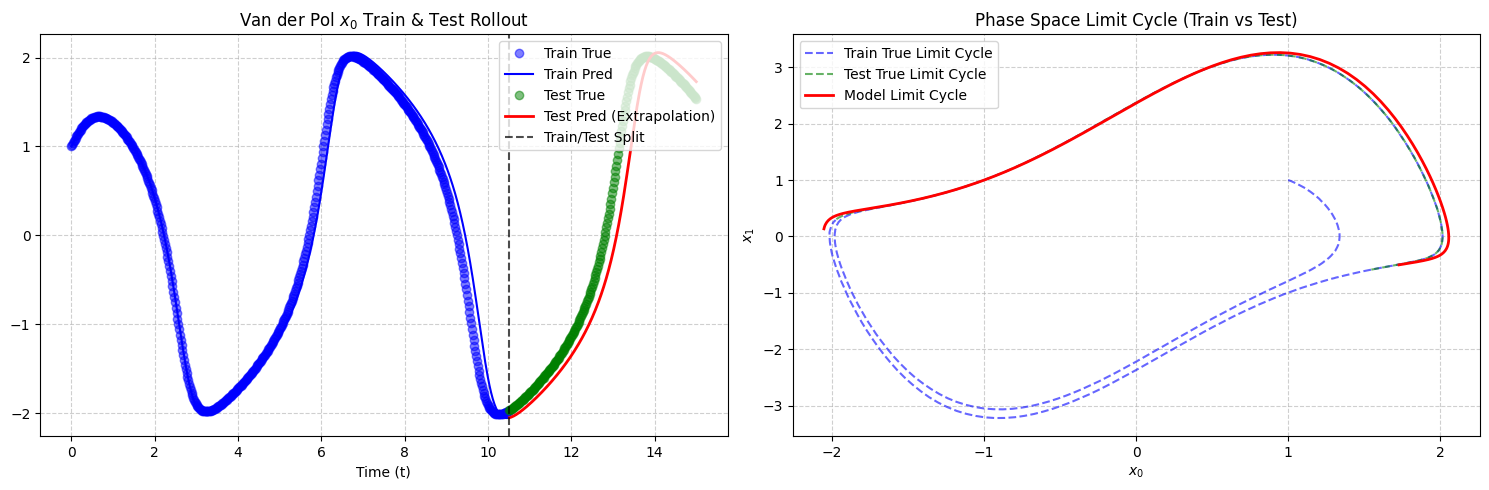

In [4]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(42)
np.random.seed(42)

class VanDerPolDataset:
    def __init__(self, u0=[1.0, 1.0], t_span=(0.0, 15.0), num_points=750, noise_level=0.0005):
        self.u0 = np.array(u0, dtype=float)
        self.t_span = t_span
        self.num_points = num_points
        self.noise_level = noise_level
        
    def ode_func(self, t, u):
        x0, x1 = u[0], u[1]
        mu = 1.5 # Gerçek Van der Pol katsayısı
        
        dx0 = x1
        dx1 = mu * (1.0 - x0**2) * x1 - x0
        return [dx0, dx1]

    def generate(self):
        t_eval = np.linspace(self.t_span[0], self.t_span[1], self.num_points)
        sol = solve_ivp(self.ode_func, self.t_span, self.u0, t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9)
        
        t_data = torch.tensor(sol.t, dtype=torch.float32).reshape(-1, 1)
        u_true = torch.tensor(sol.y.T, dtype=torch.float32)
        u_data = u_true + self.noise_level * torch.randn_like(u_true)
        dt = (t_data[1] - t_data[0]).item()
        return t_data, u_data, dt


class StructuredVanDerPolModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Öğrenilebilir mu katsayısı (başlangıç tahmini hatalı verilir)
        self.mu = nn.Parameter(torch.tensor([0.5]))
        
    def forward(self, u):
        x0, x1 = u[:, 0:1], u[:, 1:2]
        dx0 = x1
        dx1 = self.mu * (1.0 - (x0 ** 2)) * x1 - x0
        return torch.cat([dx0, dx1], dim=-1)

    def train_model(self, u_train, dt, epochs=1200, lr=0.02):
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=400, gamma=0.5)
        
        print("\n--- Training on Van der Pol Train Set ---")
        for epoch in range(epochs):
            optimizer.zero_grad()
            
            u_curr = u_train[:-1]
            u_next_true = u_train[1:]
            
            f_pred = self.forward(u_curr)
            u_next_pred = u_curr + f_pred * dt
            
            loss = torch.mean((u_next_pred - u_next_true) ** 2)
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            if (epoch + 1) % 300 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.6e} | mu: {self.mu.item():.4f}")

    def evaluate_rollout(self, u0, num_steps, dt):
        self.eval()
        preds = [u0.clone().detach()]
        curr = u0.clone().detach().unsqueeze(0)
        
        with torch.no_grad():
            for _ in range(num_steps - 1):
                f = self.forward(curr)
                next_state = curr + f * dt
                preds.append(next_state.squeeze(0).clone().detach())
                curr = next_state
                
        return torch.stack(preds)


if __name__ == "__main__":
    # 1. Veri Üretimi
    dataset_gen = VanDerPolDataset(u0=[1.0, 1.0], t_span=(0.0, 15.0), num_points=750)
    t_data, u_data, dt = dataset_gen.generate()
    
    # 2. Kronolojik Train/Test Bölünmesi (%70 Train, %30 Test)
    split_idx = int(len(t_data) * 0.7)
    
    t_train, u_train = t_data[:split_idx], u_data[:split_idx]
    t_test, u_test = t_data[split_idx:], u_data[split_idx:]
    
    print(f"Total Points: {len(t_data)} | Train Steps: {len(t_train)} | Test Steps: {len(t_test)}")

    # 3. Model Eğitimi (Sadece Train verisi ile)
    model = StructuredVanDerPolModel()
    model.train_model(u_train, dt, epochs=1200, lr=0.02)

    # 4. Rollout Çıkarımı
    print("\n--- Running Van der Pol Rollout Inference ---")
    u_full_pred = model.evaluate_rollout(u_data[0], len(t_data), dt)
    
    u_train_pred = u_full_pred[:split_idx].numpy()
    u_test_pred = u_full_pred[split_idx:].numpy()
    
    u_train_np = u_train.numpy()
    u_test_np = u_test.numpy()
    t_train_np = t_train.numpy().flatten()
    t_test_np = t_test.numpy().flatten()

    # 5. Metrik Hesaplama
    def compute_metrics(y_true, y_pred):
        mse = np.mean((y_true - y_pred) ** 2)
        rmse = np.sqrt(mse)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true, axis=0)) ** 2)
        r2 = 1.0 - (ss_res / (ss_tot + 1e-8))
        return r2, rmse

    train_r2, train_rmse = compute_metrics(u_train_np, u_train_pred)
    test_r2, test_rmse = compute_metrics(u_test_np, u_test_pred)
    
    print(f"\n[Train Results] R² Score: {train_r2:.4f} | RMSE: {train_rmse:.5f}")
    print(f"[Test Results]  R² Score: {test_r2:.4f} | RMSE: {test_rmse:.5f}")
    print(f"Learned Parameter -> mu: {model.mu.item():.4f} (True: 1.5000)")

    # 6. Görselleştirme
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    axes[0].plot(t_train_np, u_train_np[:, 0], 'bo', label='Train True', alpha=0.5)
    axes[0].plot(t_train_np, u_train_pred[:, 0], 'b-', label='Train Pred', linewidth=1.5)
    axes[0].plot(t_test_np, u_test_np[:, 0], 'go', label='Test True', alpha=0.5)
    axes[0].plot(t_test_np, u_test_pred[:, 0], 'r-', label='Test Pred (Extrapolation)', linewidth=2)
    axes[0].axvline(x=t_train_np[-1], color='k', linestyle='--', alpha=0.7, label='Train/Test Split')
    axes[0].set_title('Van der Pol $x_0$ Train & Test Rollout')
    axes[0].set_xlabel('Time (t)')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    axes[1].plot(u_train_np[:, 0], u_train_np[:, 1], 'b--', label='Train True Limit Cycle', alpha=0.6)
    axes[1].plot(u_test_np[:, 0], u_test_np[:, 1], 'g--', label='Test True Limit Cycle', alpha=0.6)
    axes[1].plot(u_test_pred[:, 0], u_test_pred[:, 1], 'r-', label='Model Limit Cycle', linewidth=2)
    axes[1].set_title('Phase Space Limit Cycle (Train vs Test)')
    axes[1].set_xlabel('$x_0$')
    axes[1].set_ylabel('$x_1$')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()